In [3]:
# CLIP Teacher
!pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-fuwnbmxj
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-fuwnbmxj
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369548 sha256=7309f7090a99143c566ea6da87f41912cb97bf29e2e6ec3b8c5660ab96af2a55
  Stored in directory: /tmp/pip-ephem-wheel-cache-6ia1khhs/wheels/cb/a8/74/5f32d6cf0407457f0f62737b6da5c14eb86b9cac476fdf630d
Successfully built clip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [clip]


In [4]:
# Major imports
import torch
import cv2
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import numpy as np
# clip pretrained
import clip

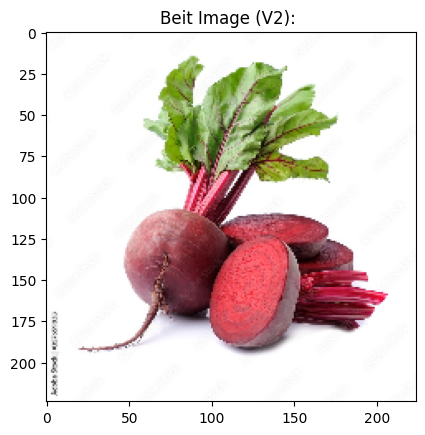

To check: torch.Size([1, 3, 224, 224])
To check patches raw shape: torch.Size([1, 16, 14, 14])


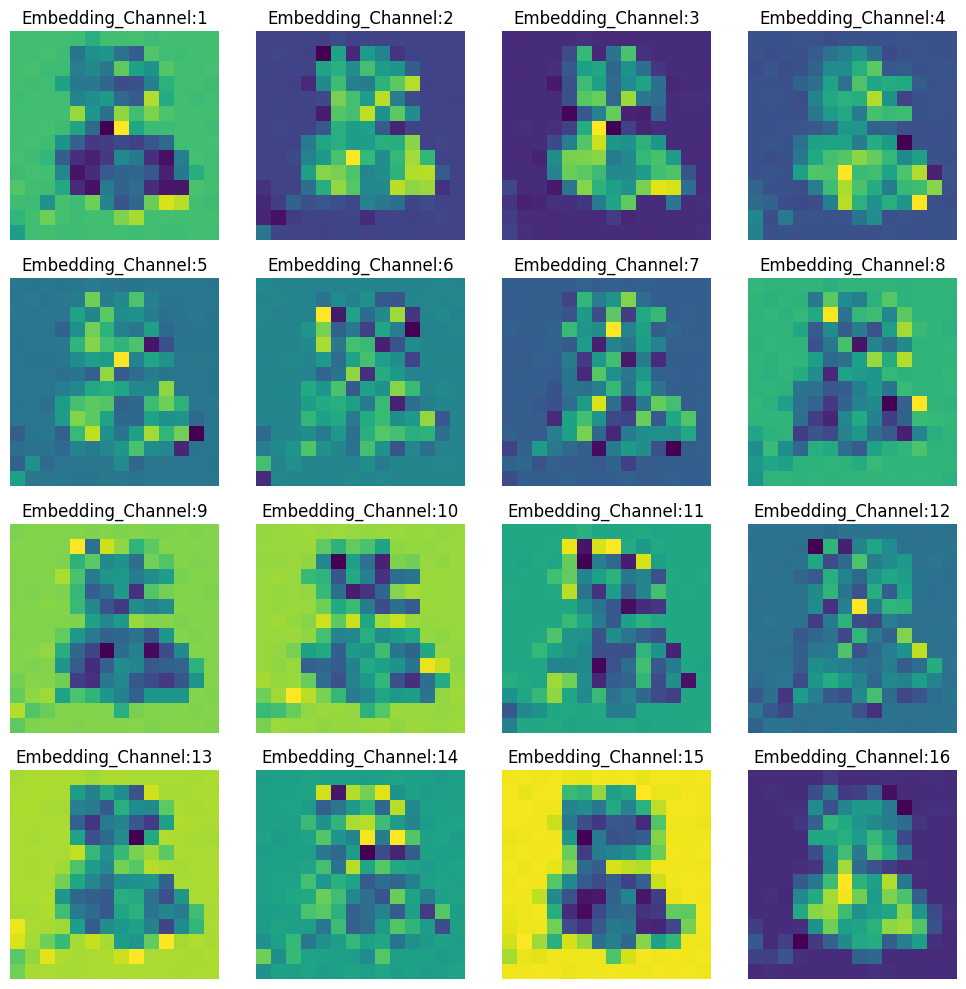

To check patches shape: torch.Size([1, 196, 16])
To check Transformer block works: torch.Size([1, 196, 16])
To check projection head works: torch.Size([1, 196, 4])
To check shape ZL2: torch.Size([1, 196, 4])
To check normalization(L2) happened: -0.20105937123298645 => -0.33043229579925537
To check the shape: torch.Size([1, 196, 128])
Let's check some vals: tensor([1.9275, 1.3318, 1.4009, 1.9836, 1.4553, 1.1711, 1.1283, 1.6994, 0.9214,
        1.3929], grad_fn=<SliceBackward0>)
Nearest code shape: torch.Size([1, 196])
Checking the indexes stored in the nearest_code: tensor([105, 105,  76,  76, 105,  33,  33,  33, 126,  64])
To check quantized shape: torch.Size([1, 196, 4])
To help llq shape: torch.Size([1, 196, 16])
To check pos_embed: torch.Size([1, 196, 16])
See the shape of H_dec (hidden representation inside dec) tensor: torch.Size([1, 196, 16])
To check H_dec_normed: torch.Size([1, 196, 16])
To check reconstructed semantic features: torch.Size([1, 196, 768])


100%|███████████████████████████████████████| 335M/335M [00:04<00:00, 76.3MiB/s]


Seeing CLIP:
<class 'clip.model.VisionTransformer'>
To check x(teacher): torch.Size([1, 196, 768])
To check T: torch.Size([1, 196, 768])
To check similarity: torch.Size([1, 196])
To see our cosine similarity: tensor([[-0.0036, -0.0291, -0.0227, -0.0235, -0.0173,  0.0388, -0.0456, -0.0073,
          0.0542, -0.0413]], grad_fn=<SliceBackward0>)
VQ-KD loss -> recon: 1.0219  vq: 0.0329  total: 1.0548
S_x is patches: torch.Size([1, 196, 16])
Checking mask:
tensor([[0., 1., 1., 1., 0., 1., 1., 0., 0., 1., 0., 0., 1., 0., 1., 1., 1., 0.,
         1., 1., 0., 0., 1., 1., 0., 0., 0., 1., 0., 0., 0., 1., 1., 0., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 0., 0., 1., 1., 1., 1., 0., 0., 0., 1., 1.,
         1., 1., 1., 0., 1., 1., 1., 1., 0., 0., 0., 1., 1., 0., 1., 1., 0., 1.,
         1., 1., 0., 1., 0., 1., 1., 1., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1.,
         0., 1., 1., 0., 0., 1., 1., 0., 1., 1., 1., 1., 0., 0., 1., 1., 1., 0.,
         1., 1., 0., 1., 1., 1., 1., 0., 1., 0., 0., 1., 1

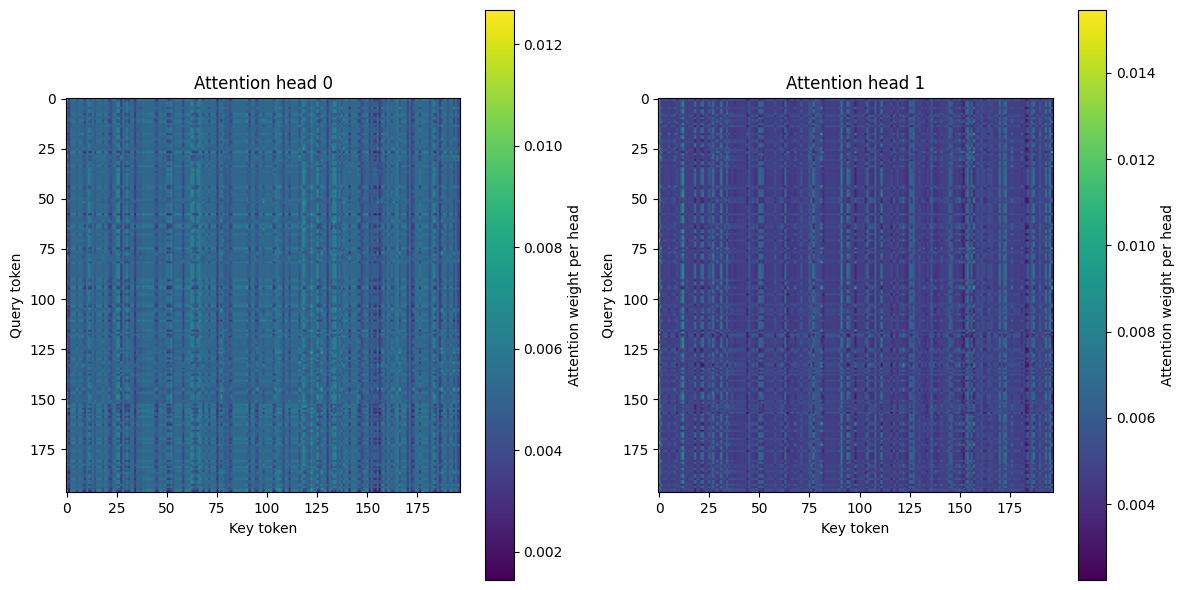

To check S_out_pp (logits over the codebook): torch.Size([1, 197, 128])
MIM loss: 4.9219


In [6]:
image = cv2.imread('beet.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image = cv2.resize(image, (224, 224))

plt.title("Beit Image (V2): ")
plt.imshow(image)
plt.show()

image_np = np.array(image)
image_torch = torch.from_numpy(image_np)
image_torch = (image_torch / 255.0).permute(2, 0, 1).unsqueeze(0)
print(f"To check: {image_torch.shape}")

# patch_embedding
embed_dim = 16
patch_size = 16

patch_embed = nn.Conv2d(in_channels = 3, out_channels = embed_dim, kernel_size = patch_size, stride = patch_size, padding = 'valid')
patches = patch_embed(image_torch)
print(f"To check patches raw shape: {patches.shape}")

# Let us look at the patch_embed feature visualization once:

fig, axes = plt.subplots(4, 4, figsize = (10, 10))

for i, ax in enumerate(axes.flat):
  ax.imshow(patches[0][i].detach().numpy())
  ax.set_title(f"Embedding_Channel:{i+1}")
  ax.axis('off')

plt.tight_layout()
plt.show()

B, _, grid_dim, _ = patches.shape
patches = patches.reshape(B, grid_dim**2, embed_dim)
print(f"To check patches shape: {patches.shape}")

# adding positional embedding
num_patches = grid_dim**2
enc_pos_embed = nn.Parameter(torch.zeros(1, num_patches, embed_dim)) # lape
nn.init.trunc_normal_(enc_pos_embed, std = 0.02)
patches = patches + enc_pos_embed

# Vector quantized knowledge distillation branch first

# we need to pass it through a vit encoder with 12 transformer blocks

# let us create the block to pass it through that

class BeiT_block(nn.Module):
  def __init__(self, embed_dim, n_heads):
    super().__init__()
    self.embed_dim = embed_dim
    self.n_heads = n_heads
    self.d_head = self.embed_dim // self.n_heads
    self.pre_ln = nn.LayerNorm(self.embed_dim)
    self.w_q = nn.Linear(embed_dim, embed_dim)
    self.w_k = nn.Linear(embed_dim, embed_dim)
    self.w_v = nn.Linear(embed_dim, embed_dim)
    self.w_o = nn.Linear(embed_dim, embed_dim)
    self.ln_mlp = nn.LayerNorm(embed_dim)
    self.mlp = nn.Sequential(
        nn.Linear(embed_dim, embed_dim*4),
        nn.GELU(),
        nn.Linear(embed_dim*4, embed_dim)
    )


  def forward(self, X):
    normed_X = self.pre_ln(X)
    B, grid_dim, _ = normed_X.shape

    Q = self.w_q(normed_X)
    K = self.w_k(normed_X)
    V = self.w_v(normed_X)

    # reshaping the vectors

    Q = Q.reshape(B, grid_dim, self.n_heads, self.d_head).transpose(1, 2)
    K = K.reshape(B, grid_dim, self.n_heads, self.d_head).transpose(1, 2)
    V = V.reshape(B, grid_dim, self.n_heads, self.d_head).transpose(1, 2)

    attn_scores = torch.matmul(Q, K.transpose(-2, -1))/torch.sqrt(torch.tensor(self.d_head))
    attn_scores = F.softmax(attn_scores, dim = -1)

    context = torch.matmul(attn_scores, V)

    context = context.transpose(1, 2).contiguous().reshape(B, grid_dim, self.embed_dim)
    # do we still pass contiguous()

    output = self.w_o(context)

    X = X + output

    X = X + self.mlp(self.ln_mlp(X))

    return X


Block1 = BeiT_block(embed_dim = 16, n_heads = 2)
X_out = Block1(patches)
print(f"To check Transformer block works: {X_out.shape}")


# now we use a projection head for VQ projection

projection_dim = embed_dim // 4 # chosen arbitrarily

projection_head = nn.Linear(embed_dim, projection_dim)

Z = projection_head(X_out)
print(f"To check projection head works: {Z.shape}")

# perform L2 normalize
# implement own once
ZL2 = F.normalize(Z, p = 2, dim = -1)

print(f"To check shape ZL2: {ZL2.shape}")
print(f"To check normalization(L2) happened: {Z[0][0][0]} => {ZL2[0][0][0]}")


# Let's move ahead to creating the codebook

num_codes = 128 # let us keep it small for our implementation
# The original implementation uses 8192 as the num_codes
codebook_dim = projection_dim
codebook = nn.Parameter(torch.randn(num_codes, codebook_dim))

#L2 normalize the codebook
codebook_norm = F.normalize(codebook, p = 2, dim = -1)

# now let us calculate distances between each codebook vector and every patch

distances = torch.cdist(ZL2, codebook_norm, p = 2)
print(f"To check the shape: {distances.shape}")
print(f"Let's check some vals: {distances[0][0][0:10]}")

# Now we will move on to finding the nearest codebook vector

nearest_code = torch.argmin(distances, dim = -1) # these should help us get our MiM targets
print(f"Nearest code shape: {nearest_code.shape}")

# we choose the nearest codebook vector out of 128
# Now we will get the actual quantized vectors

print(f"Checking the indexes stored in the nearest_code: {nearest_code[0][0:10]}")

quantized = codebook_norm[nearest_code]
print(f"To check quantized shape: {quantized.shape}")
# [MEDIUM]
# SO basically we chose 196 vectors with projection_dim

# Let us get to our VQ-KD Decoder

# check positional embedding in encoder too
quantized_st = ZL2 + (quantized - ZL2).detach()
beta = 0.25  # standard VQ-VAE commitment weight
codebook_loss = F.mse_loss(quantized, ZL2.detach())
commitment_loss = F.mse_loss(ZL2, quantized.detach())
vq_loss = codebook_loss + beta * commitment_loss

class Beit_dec_block(nn.Module):
  def __init__(self, Decoder_dim, projection_dim, grid_dim):
    super().__init__()
    self.projection_dim = projection_dim
    self.decoder_dim = Decoder_dim
    self.Linear_layer = nn.Linear(projection_dim, Decoder_dim)
    # Add positional embedding in forward
    # 3 transformer blocks we will use one
    self.pre_ln = nn.LayerNorm(self.decoder_dim)
    # pos_embed
    self.pos_embed = nn.Parameter(torch.randn(1, grid_dim, self.decoder_dim))
    nn.init.trunc_normal_(self.pos_embed, std = 0.02)
    # MHSA
    self.n_heads = 2
    self.d_head = self.decoder_dim // self.n_heads
    self.w_q = nn.Linear(self.decoder_dim, self.decoder_dim) # query
    self.w_k = nn.Linear(self.decoder_dim, self.decoder_dim) # Key
    self.w_v = nn.Linear(self.decoder_dim, self.decoder_dim) # Value
    self.w_o = nn.Linear(self.decoder_dim, self.decoder_dim) # output gate
    self.ln_mlp = nn.LayerNorm(self.decoder_dim)
    self.mlp = nn.Sequential(
        nn.Linear(self.decoder_dim, self.decoder_dim*4),
        nn.GELU(),
        nn.Linear(self.decoder_dim*4, self.decoder_dim)
    )

    self.ln = nn.LayerNorm(self.decoder_dim)

  def forward(self, quantized):
    llq = self.Linear_layer(quantized)
    # pos_embed_start

    # we will use absolute positonal embeddings as given
    print(f"To help llq shape: {llq.shape}")
    print(f"To check pos_embed: {self.pos_embed.shape}")

    llq = llq + self.pos_embed

    # pos_embed_end
    X = self.pre_ln(llq)

    # MHSA
    B, grid_dim, _ = X.shape
    Q, K, V = self.w_q(X), self.w_k(X), self.w_v(X)
    Q = Q.reshape(B, grid_dim, self.n_heads, self.d_head).transpose(1, 2)
    K = K.reshape(B, grid_dim, self.n_heads, self.d_head).transpose(1, 2)
    V = V.reshape(B, grid_dim, self.n_heads, self.d_head).transpose(1, 2)

    attn_scores = torch.matmul(Q, K.transpose(-2, -1))/torch.sqrt(torch.tensor(self.d_head))
    attn_wts = F.softmax(attn_scores, dim = -1)

    # why not CLS token in this one cause no classification?
    # also dropout yes or no??
    context = torch.matmul(attn_wts, V)

    context = context.transpose(1, 2).contiguous().reshape(B, grid_dim, self.decoder_dim)

    output = self.w_o(context)

    X = X + output # residual add 1

    x_ln = self.ln_mlp(X)

    X = X + self.mlp(x_ln) # residual add 2

    return X


Decoder_dim, teacher_dim= 16, 768 # clip [768]
Dec_block = Beit_dec_block(Decoder_dim, projection_dim, grid_dim*grid_dim)
H_dec = Dec_block(quantized_st)

print(f"See the shape of H_dec (hidden representation inside dec) tensor: {H_dec.shape}")
# Teacher how to choose??
# teacher dim put in the wrong place fix

Ln_teacher = nn.LayerNorm(Decoder_dim)
H_dec_normed = Ln_teacher(H_dec)
print(f"To check H_dec_normed: {H_dec_normed.shape}")

# projecting it to teacher_dim

teacher_layer = nn.Linear(Decoder_dim, teacher_dim)
recon_semantic_feats = teacher_layer(H_dec_normed)
print(f"To check reconstructed semantic features: {recon_semantic_feats.shape}")

# Let us move on to the teacher network branch now

# we will be using a pretrained clip vit-base as teacher

device = "cuda" if torch.cuda.is_available() else "cpu"

teacher, preprocess = clip.load(
    "ViT-B/16",
    device = device
)

teacher.eval()

for param in teacher.parameters():
  param.requires_grad = False

print("Seeing CLIP:")
# print(teacher.visual)
print(type(teacher.visual))


clip_mean = torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(1, 3, 1, 1)
clip_std = torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(1, 3, 1, 1)
x = ((image_torch - clip_mean) / clip_std).to(device)
x = x.to(teacher.dtype)


with torch.no_grad():
  # patch_embed
  x = teacher.visual.conv1(x)

  B, C, H, W = x.shape

  x = x.reshape(B, C, H*W).permute(0, 2, 1)
  print(f"To check x(teacher): {x.shape}")

  # adding cls token

  cls_token = teacher.visual.class_embedding.to(teacher.dtype)
  cls_token = cls_token.unsqueeze(0).unsqueeze(0)
  cls_token = cls_token.expand(B, -1, -1)

  x = torch.cat([cls_token, x], dim = 1)

  # pos embed
  x = x + teacher.visual.positional_embedding.to(teacher.dtype) # unknown line
  x = teacher.visual.ln_pre(x)
  #clip transformer
  x = x.permute(1, 0, 2)

  x = teacher.visual.transformer(x)

  x = x.permute(1, 0, 2)

  x = teacher.visual.ln_post(x) # CHANGED: normalize every token the way CLIP does before its projection

  # drop cls

  T = x[:, 1:, :].float().cpu() # CHANGED: back to fp32 + same device as recon_semantic_feats
print(f"To check T: {T.shape}")

# Time for cosine loss

T_cap = recon_semantic_feats
# dot product
T_cap_L2 = F.normalize(T_cap, p = 2, dim = -1)
T_L2 = F.normalize(T, p = 2, dim = -1)
similarity = torch.sum(T_cap_L2 * T_L2, dim = -1)
print(f"To check similarity: {similarity.shape}")
print(f"To see our cosine similarity: {similarity[:, 0:10]}")

recon_loss = (1 - similarity).mean() # how do we turn things that can be called with .backward()

vqkd_loss = recon_loss + vq_loss
print(f"VQ-KD loss -> recon: {recon_loss.item():.4f}  vq: {vq_loss.item():.4f}  total: {vqkd_loss.item():.4f}")

# LOSS done

# Let us do the Beit v2 student network branch

# patch embed
# tokenizer's embedding which already had enc_pos_embed added (double pos embed)
S_patch_embed = nn.Conv2d(in_channels = 3, out_channels = embed_dim, kernel_size = patch_size, stride = patch_size, padding = 'valid')
S_x = S_patch_embed(image_torch).flatten(2).transpose(1, 2)
print(f"S_x is patches: {S_x.shape}")

# random masking
B, grid_dim, _ = S_x.shape
num_zeros = int(0.4*196)

mask = torch.ones(B, grid_dim)
for b in range(B):
  idx_b = torch.randperm(grid_dim)[:num_zeros]
  mask[b, idx_b] = 0
print(f"Checking mask:")
print(mask)

mask_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
nn.init.trunc_normal_(mask_token, std = 0.02)

bool_mask = (mask == 0).unsqueeze(-1) # true where it is masked
S_x_masked = torch.where(bool_mask, mask_token.expand_as(S_x), S_x)
print(f"To check S_x_masked: {S_x_masked[:, 0, :]}")

# replacing masked patches

# adding CLS
cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
nn.init.trunc_normal_(cls_token, std = 0.02)
S_x_cls = torch.cat([cls_token.expand(B, -1, -1), S_x_masked], dim = 1)
# positional embedding (lape)

pos_embed = nn.Parameter(torch.zeros(1, grid_dim+1, embed_dim))
nn.init.trunc_normal_(pos_embed, std = 0.02)
# initialising pos_embed

SX = S_x_cls + pos_embed
print(f"To check SX: {SX.shape}")

class Beit_S_block(nn.Module):
  def __init__(self, embed_dim, n_heads):
    super().__init__()
    self.embed_dim = embed_dim
    self.pre_ln = nn.LayerNorm(self.embed_dim)
    self.n_heads = n_heads
    self.d_head = embed_dim // self.n_heads
    self.w_q = nn.Linear(self.embed_dim, self.embed_dim)
    self.w_k = nn.Linear(self.embed_dim, self.embed_dim)
    self.w_v = nn.Linear(self.embed_dim, self.embed_dim)
    self.w_o = nn.Linear(self.embed_dim, self.embed_dim)
    self.mlp_ln = nn.LayerNorm(self.embed_dim)
    self.mlp = nn.Sequential(
        nn.Linear(embed_dim, 4*embed_dim),
        nn.GELU(),
        nn.Linear(4*embed_dim, embed_dim),
    )

    # .train() / .eval() now control dropout properly


  def forward(self, X):
    X_normed = self.pre_ln(X)
    # MSA starts
    B, G, E = X.shape
    Q, K, V = self.w_q(X_normed), self.w_k(X_normed), self.w_v(X_normed)
    Q = Q.reshape(B, G, self.n_heads, self.d_head).transpose(1, 2)
    K = K.reshape(B, G, self.n_heads, self.d_head).transpose(1, 2)
    V = V.reshape(B, G, self.n_heads, self.d_head).transpose(1, 2)

    attn_scores = torch.matmul(Q, K.transpose(-2, -1))/torch.sqrt(torch.tensor(self.d_head))
    attn_wts = F.softmax(attn_scores, dim = -1)

    self.last_attn = attn_wts.detach()

    attn_wts = F.dropout(attn_wts, 0.1, training = self.training)



    context = attn_wts @ V
    context = context.transpose(1, 2).contiguous().reshape(B, G, E)

    output = self.w_o(context)

    # residual
    X = X + output

    X_mlp_ln = self.mlp_ln(X)

    # residual again + passing it thru mlp
    X = X + self.mlp(X_mlp_ln)

    return X

Beit_Student_block = Beit_S_block(embed_dim = embed_dim, n_heads = 2)
S_out = Beit_Student_block(SX)

print(f"To check S_out: {S_out.shape}")

# To visualize the heads (should be a practice)
fig, axes = plt.subplots(1, Beit_Student_block.n_heads, figsize = (12, 6))

for h in range(Beit_Student_block.n_heads):

  im = axes[h].imshow(Beit_Student_block.last_attn[0, h].numpy())
  axes[h].set_title(f"Attention head {h}")
  axes[h].set_xlabel("Key token")
  axes[h].set_ylabel("Query token")

  fig.colorbar(im, ax = axes[h], label = "Attention weight per head")

plt.tight_layout()
plt.show()

S_final_ln = nn.LayerNorm(embed_dim)

pred_proj_head = nn.Linear(embed_dim, num_codes)
S_out_pp = pred_proj_head(S_out)
print(f"To check S_out_pp (logits over the codebook): {S_out_pp.shape}")


S_out_pp_patches = S_out_pp[:, 1:, :]
mim_bool_mask = (mask == 0)
mim_targets = nearest_code.detach()  # these are labels, not something to backprop into
loss_mim = F.cross_entropy(S_out_pp_patches[mim_bool_mask], mim_targets[mim_bool_mask])
print(f"MIM loss: {loss_mim.item():.4f}")

# finish medium post